# Практична робота №1. Інтелектуальна обробка даних
Варіант 38, файл `A38.txt`: 12 каналів, N = 5000 значень у кожному.

Що треба зробити:
1. Попередній аналіз (графіки, статистика, гістограми, перевірка на нормальність, нормалізація)
2. Однофакторний дисперсійний аналіз
3. Двофакторний дисперсійний аналіз
4. Кореляційний аналіз
5. Спектральний аналіз (Фур'є)

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style='whitegrid')

alpha = 0.05
fs = 500   # частота дискретизації: сигнал схожий на ЕКГ (12 відведень), тому беру 500 Гц -> запис 10 с

pd.set_option('display.float_format', lambda v: f'{v:.4f}')

data = np.loadtxt('data/A38.txt', delimiter=',')
N, K = data.shape
channels = [f'ch{i + 1}' for i in range(K)]
df = pd.DataFrame(data, columns=channels)
print(N, K)
df.head()

5000 12


,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8,ch9,ch10,ch11,ch12
0,-6.1950,78.0330,94.1860,-35.7060,-50.5190,82.6640,59.3100,82.5360,83.9200,87.9220,87.3310,76.2480
1,-7.8138,82.0110,99.7420,-37.4490,-53.7460,86.9170,58.8940,79.4390,81.7840,83.3030,84.9250,71.4180
2,-8.4808,85.1350,103.4900,-39.1190,-55.6880,89.9030,56.9140,74.0940,77.6270,77.5600,80.3650,65.6060
3,-7.7429,86.0610,103.6400,-40.2170,-55.2420,90.1020,52.4890,65.3810,70.3060,70.0160,72.4800,58.2100
4,-6.1061,83.3210,99.2210,-39.7700,-52.1260,86.3190,45.8760,53.8380,60.1170,60.8490,61.6570,49.3680


## 1. Попередній аналіз

### 1.1. Графіки

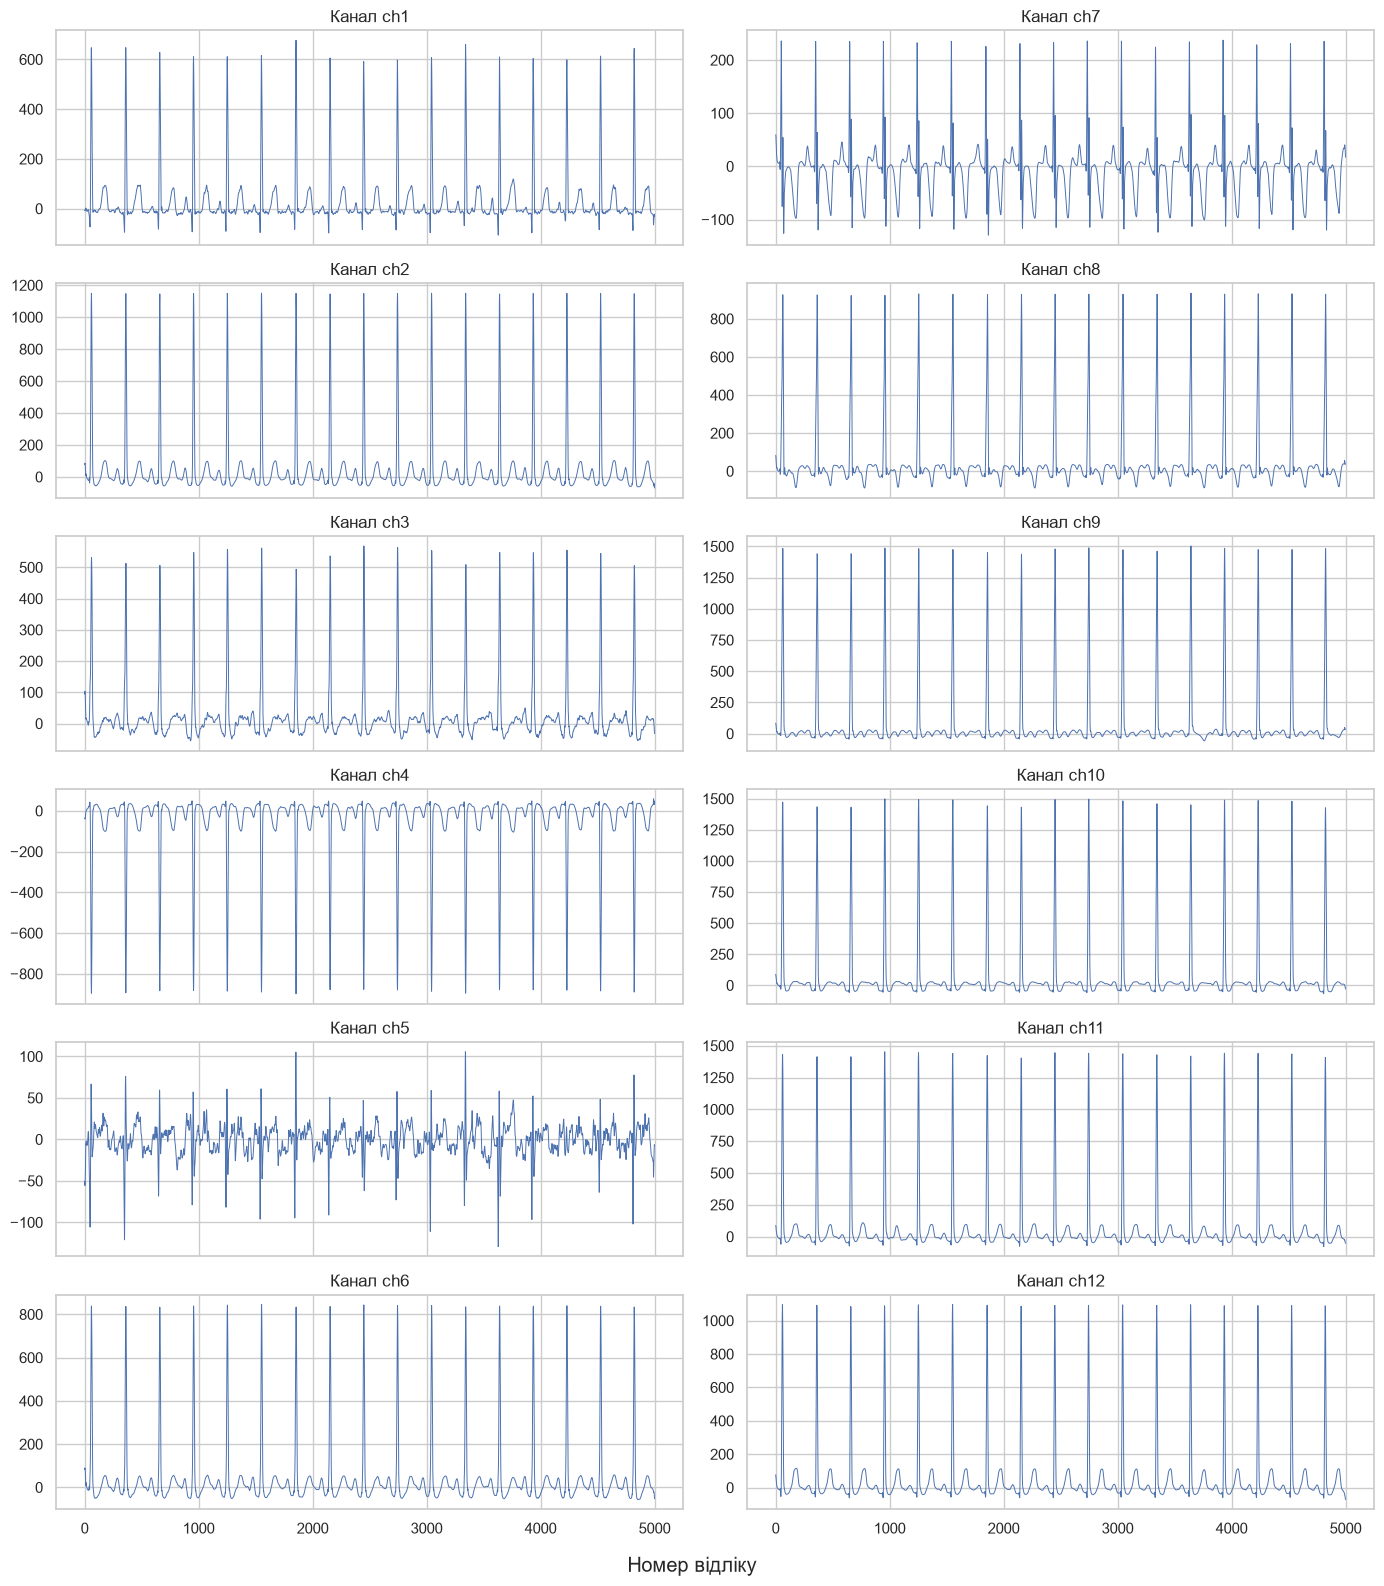

In [2]:
t = np.arange(N)
# канали 1-6 у лівому стовпці, 7-12 у правому
fig, axes = plt.subplots(6, 2, figsize=(14, 16), sharex=True)
for ax, ch in zip(axes.T.ravel(), channels):
    sns.lineplot(x=t, y=df[ch], ax=ax, lw=0.7)
    ax.set_title(f'Канал {ch}')
    ax.set_ylabel('')
fig.supxlabel('Номер відліку')
fig.tight_layout()
plt.show()

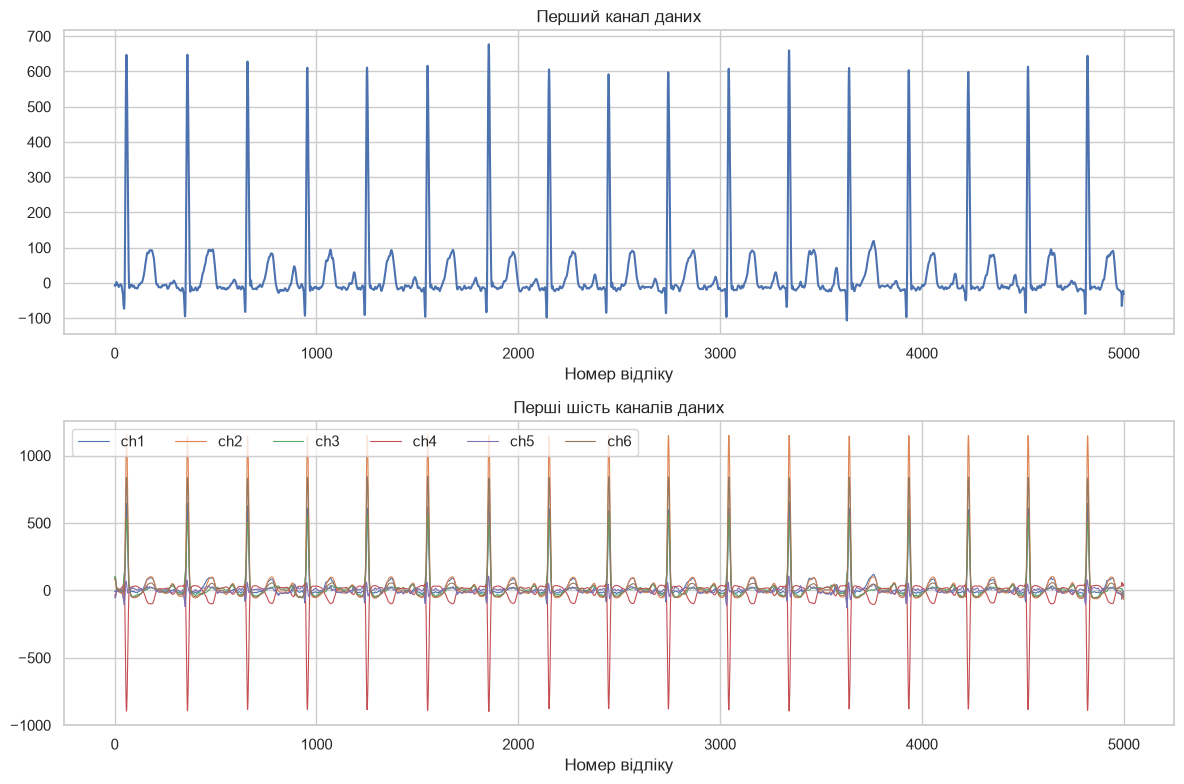

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
sns.lineplot(x=t, y=df['ch1'], ax=axes[0])
axes[0].set_title('Перший канал даних')
sns.lineplot(data=df[channels[:6]], ax=axes[1], lw=0.8, dashes=False)
axes[1].set_title('Перші шість каналів даних')
axes[1].legend(ncol=6)
for ax in axes:
    ax.set_xlabel('Номер відліку')
    ax.set_ylabel('')
fig.tight_layout()
plt.show()

**Модуль сигналу**

Рахую за евклідовою метрикою по всіх 12 каналах: $M_i = \sqrt{\sum_{j=1}^{12} x_{ij}^2}$

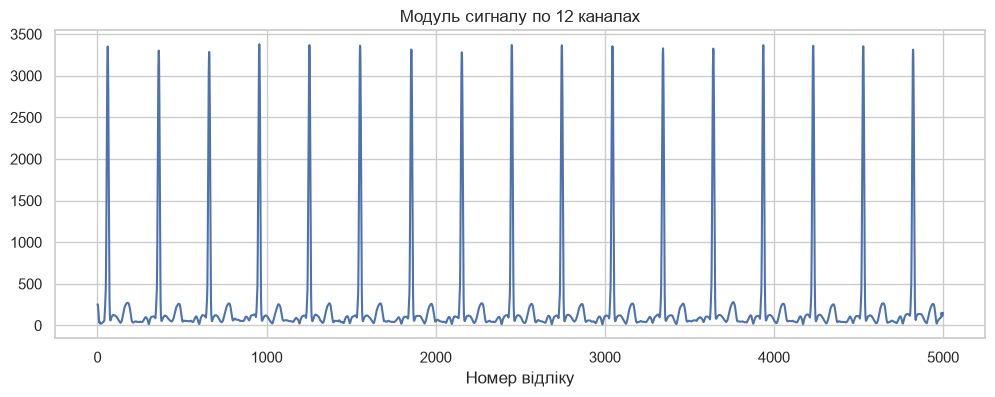

In [4]:
module = np.sqrt((data ** 2).sum(axis=1))
df_ext = df.copy()
df_ext['module'] = module

plt.figure(figsize=(12, 4))
sns.lineplot(x=t, y=module)
plt.title('Модуль сигналу по 12 каналах')
plt.xlabel('Номер відліку')
plt.show()

### 1.2. Статистичні параметри

Середнє гармонічне і геометричне рахуються тільки для додатних чисел, а в каналах є від'ємні значення.
Тому зсуваю дані: $x' = x - \min x + 1$, рахую середнє і потім віднімаю зсув назад.

Середня різниця Джині: $G_{md} = \frac{2}{N(N-1)}\sum_{i=1}^{N}(2i-N-1)\,x_{(i)}$ (по відсортованому ряду).

Мода для неперервних даних: $Mo = x_L + h\frac{f_m - f_{m-1}}{(f_m-f_{m-1}) + (f_m - f_{m+1})}$, гістограма на 50 інтервалів.

In [5]:
def shift_data(x):
    # зсув, щоб усі значення були > 0
    if x.min() > 0:
        return x, 0
    s = 1 - x.min()
    return x + s, s


def harm_mean(x):
    xs, s = shift_data(x)
    return stats.hmean(xs) - s


def geom_mean(x):
    xs, s = shift_data(x)
    return stats.gmean(xs) - s


def gini(x):
    xs = np.sort(x)
    n = len(xs)
    i = np.arange(1, n + 1)
    return 2 * np.sum((2 * i - n - 1) * xs) / (n * (n - 1))


def mode(x, bins=50):
    f, edges = np.histogram(x, bins=bins)
    m = np.argmax(f)
    h = edges[1] - edges[0]
    f_prev = f[m - 1] if m > 0 else 0
    f_next = f[m + 1] if m < len(f) - 1 else 0
    return edges[m] + h * (f[m] - f_prev) / ((f[m] - f_prev) + (f[m] - f_next))


def my_stats(x):
    return {
        'середнє': np.mean(x),
        'сер. гармонічне': harm_mean(x),
        'сер. геометричне': geom_mean(x),
        'дисперсія': np.var(x, ddof=1),
        'СКВ': np.std(x, ddof=1),
        'різниця Джині': gini(x),
        'мода': mode(x),
        'медіана': np.median(x),
        'асиметрія': stats.skew(x),
        'ексцес': stats.kurtosis(x),
        'min': np.min(x),
        'max': np.max(x),
    }


desc = pd.DataFrame({col: my_stats(df_ext[col].values) for col in df_ext.columns})
desc

,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8,ch9,ch10,ch11,ch12,module
середнє,27.6762,46.9822,23.2767,-38.3901,-0.6045,34.3244,-4.8635,40.9651,65.7490,63.3471,62.1760,47.4704,244.4997
сер. гармонічне,-4.6385,-25.5395,-15.9370,-409.3318,-9.6931,-25.8208,-33.3634,-32.6516,-9.4143,-14.6567,-13.1576,-11.9250,77.4978
сер. геометричне,8.9032,-4.5973,-0.3557,-83.6839,-2.7256,-4.9079,-15.7165,2.0915,7.5217,4.3223,6.2990,4.5897,107.0101
дисперсія,11552.3354,40392.7311,9646.8434,23620.6011,400.0899,22052.3470,2390.6492,26411.4689,66364.2190,66756.6284,62675.2466,35401.6978,330201.5967
СКВ,107.4818,200.9794,98.2183,153.6900,20.0022,148.5003,48.8943,162.5161,257.6125,258.3730,250.3502,188.1534,574.6317
різниця Джині,75.4843,133.5045,69.2144,103.6831,20.4552,98.9731,46.4073,108.2189,145.3991,147.6720,151.6789,122.3397,327.4710
мода,-14.7574,-11.6421,13.3720,21.6633,7.8133,-0.3195,3.0962,18.6547,10.7168,10.4573,-8.5575,-20.8399,71.1245
медіана,-8.7935,-10.0970,7.5173,10.8515,0.3448,0.8711,0.6629,8.0452,6.4460,11.7380,-2.9740,-4.7168,95.9679
асиметрія,3.9125,4.0882,3.8513,-4.0469,-0.8301,4.0662,1.2728,3.8463,4.1492,4.1986,4.2170,4.1594,4.2083
ексцес,16.2651,16.8365,15.2395,16.7074,6.2811,16.6089,6.3294,15.0446,16.7087,17.1057,17.4588,17.4698,17.1287


In [6]:
# окремо для модуля сигналу
desc['module']

середнє               244.4997
сер. гармонічне        77.4978
сер. геометричне      107.0101
дисперсія          330201.5967
СКВ                   574.6317
різниця Джині         327.4710
мода                   71.1245
медіана                95.9679
асиметрія               4.2083
ексцес                 17.1287
min                    14.6840
max                  3378.0858
Name: module, dtype: float64

### 1.3. Гістограми та перевірка нормальності

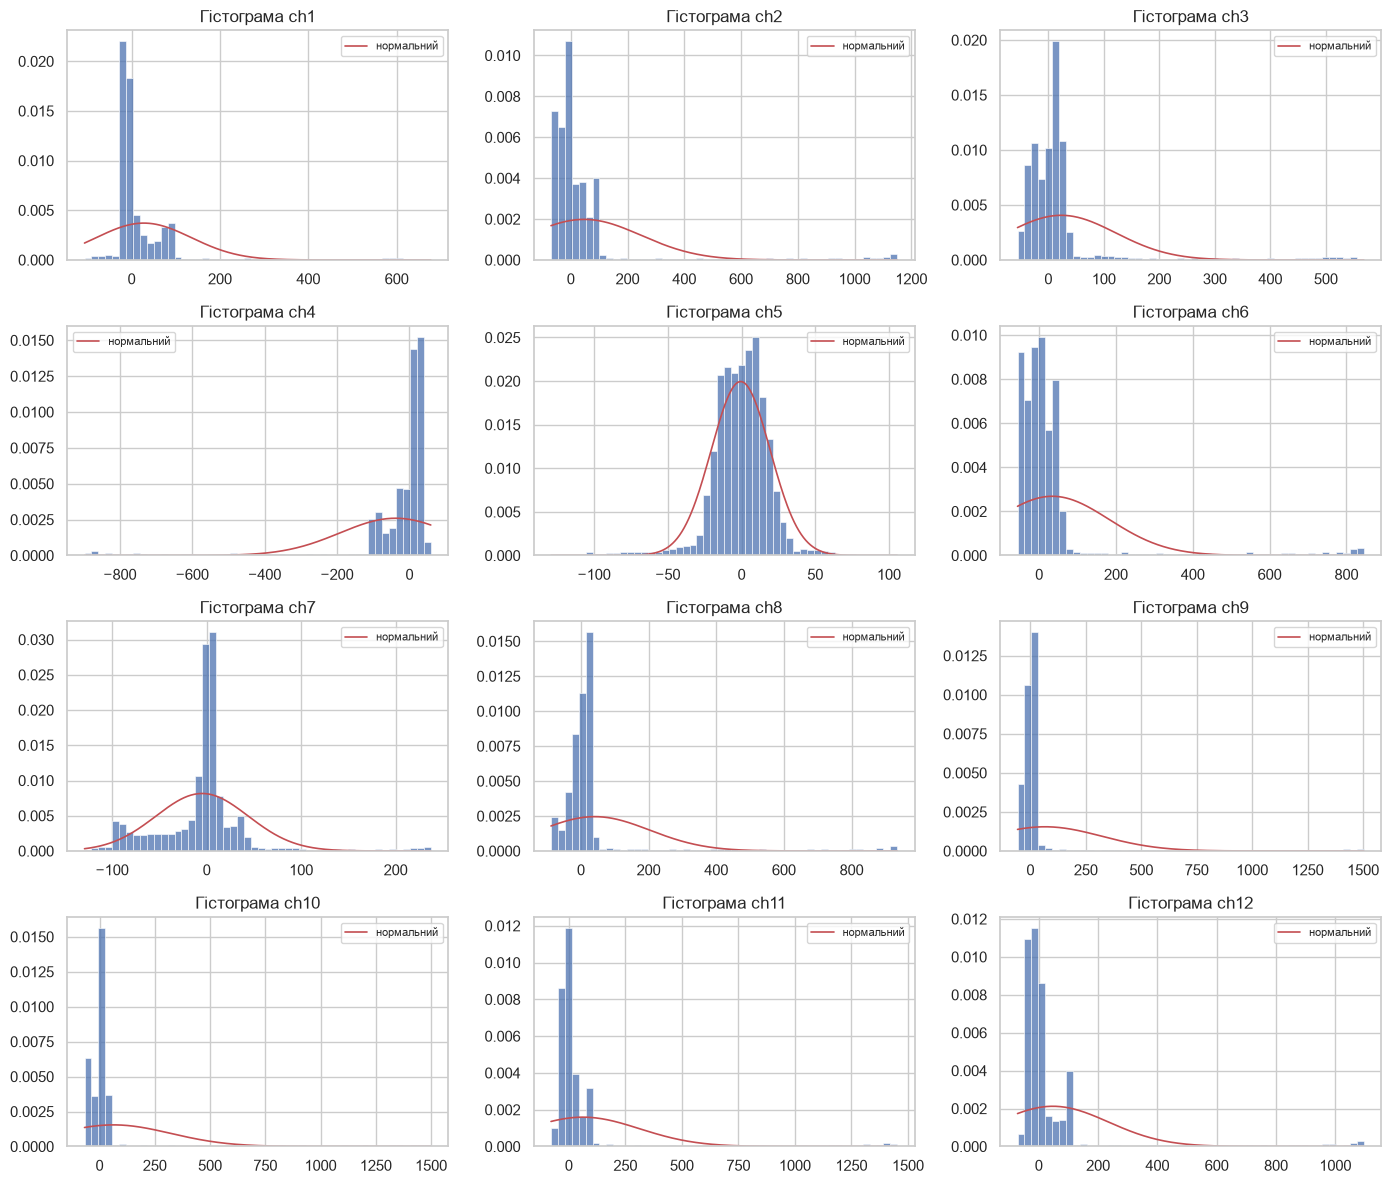

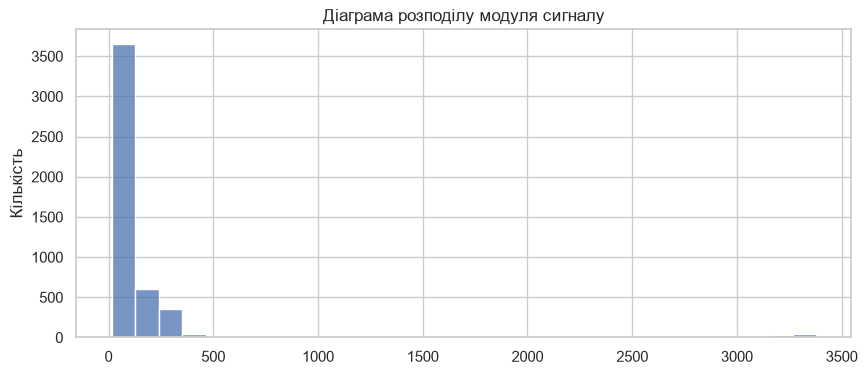

In [7]:
# червона крива - нормальна густина з тими ж середнім і СКВ
fig, axes = plt.subplots(4, 3, figsize=(14, 12))
for ax, ch in zip(axes.ravel(), channels):
    x = df[ch]
    sns.histplot(x, bins=50, stat='density', ax=ax)
    xx = np.linspace(x.min(), x.max(), 300)
    ax.plot(xx, stats.norm.pdf(xx, x.mean(), x.std()), 'r', lw=1.2, label='нормальний')
    ax.set_title(f'Гістограма {ch}')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.histplot(module, bins=30)
plt.title('Діаграма розподілу модуля сигналу')
plt.ylabel('Кількість')
plt.show()

**Перевірка на нормальний розподіл**

$H_0$: розподіл нормальний. Критерій $\chi^2$ Пірсона: $\chi^2 = \sum_k \frac{(n_k - np_k)^2}{np_k}$,
інтервали, де $np_k < 5$, об'єдную з сусідніми. Ступенів свободи $\nu = r - 3$ (два параметри оцінені по вибірці).
Якщо $\chi^2 > \chi^2_{крит}$, гіпотеза відхиляється.

Для порівняння ще критерій Д'Агостіно (`stats.normaltest`).

In [8]:
def chi2_test(x, bins=30):
    n = len(x)
    mu, sigma = x.mean(), x.std(ddof=1)
    counts, edges = np.histogram(x, bins=bins)
    cdf = stats.norm.cdf(edges, mu, sigma)
    cdf[0], cdf[-1] = 0, 1   # крайні інтервали до -inf і +inf
    expected = n * np.diff(cdf)

    # об'єднуємо інтервали з np < 5
    obs, exp = [], []
    o_sum, e_sum = 0, 0
    for o, e in zip(counts, expected):
        o_sum += o
        e_sum += e
        if e_sum >= 5:
            obs.append(o_sum)
            exp.append(e_sum)
            o_sum, e_sum = 0, 0
    obs[-1] += o_sum
    exp[-1] += e_sum
    obs, exp = np.array(obs), np.array(exp)

    chi2 = np.sum((obs - exp) ** 2 / exp)
    dof = len(obs) - 3
    crit = stats.chi2.ppf(1 - alpha, dof)
    return chi2, dof, crit


res = []
for col in df_ext.columns:
    x = df_ext[col].values
    chi2, dof, crit = chi2_test(x)
    p = stats.normaltest(x).pvalue
    res.append([col, chi2, dof, crit, 'так' if chi2 < crit else 'ні', p])
normality = pd.DataFrame(res, columns=['змінна', 'χ²', 'ν', 'χ²крит', 'нормальний?', "p (Д'Агостіно)"])
normality

,змінна,χ²,ν,χ²крит,нормальний?,p (Д'Агостіно)
0,ch1,19567.5952,15,24.9958,ні,0.0000
1,ch2,12388.7075,16,26.2962,ні,0.0000
2,ch3,13577.1415,16,26.2962,ні,0.0000
3,ch4,11339.8100,15,24.9958,ні,0.0000
4,ch5,1215.5818,14,23.6848,ні,0.0000
5,ch6,11665.2824,16,26.2962,ні,0.0000
6,ch7,6135.2344,20,31.4104,ні,0.0000
7,ch8,15948.0029,16,26.2962,ні,0.0000
8,ch9,20895.1017,15,24.9958,ні,0.0000
9,ch10,26318.3008,15,24.9958,ні,0.0000


Для всіх каналів і для модуля $\chi^2$ набагато більше за критичне, тому гіпотеза про нормальний розподіл відхиляється.
Д'Агостіно теж дає p ≈ 0. Це видно і з гістограм: сигнал складається з гострих піків, розподіли дуже несиметричні (асиметрія близько ±4, ексцес 15-17).

### 1.4. Нормалізація

$x^*_{ij} = \frac{x_{ij} - \bar x_j}{\sigma_{x_j}}$, після цього в кожному каналі середнє 0, дисперсія 1.

In [9]:
data_norm = (data - data.mean(axis=0)) / data.std(axis=0)
df_norm = pd.DataFrame(data_norm, columns=channels)
print(df_norm.mean().round(6).values)
print(df_norm.var(ddof=0).round(6).values)

[ 0.  0. -0.  0. -0.  0. -0.  0. -0.  0. -0. -0.]
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Однофакторний дисперсійний аналіз

Фактор A - номер каналу, k = 12 рівнів, на кожному n = 5000 значень.
$H_0$: середні по всіх каналах однакові.

$S_i^2 = \frac{1}{n-1}\sum_{j=1}^{n}(x_{ij} - \bar x_i)^2$

In [10]:
X = data.T          # рядок = канал (рівень фактора)
k, n = X.shape
means_i = X.mean(axis=1)
S2_i = X.var(axis=1, ddof=1)
pd.DataFrame({'x̄_i': means_i, 'S²_i': S2_i}, index=channels).T

,ch1,ch2,ch3,ch4,ch5,ch6,ch7,ch8,ch9,ch10,ch11,ch12
x̄_i,27.6762,46.9822,23.2767,-38.3901,-0.6045,34.3244,-4.8635,40.9651,65.7490,63.3471,62.1760,47.4704
S²_i,11552.3354,40392.7311,9646.8434,23620.6011,400.0899,22052.3470,2390.6492,26411.4689,66364.2190,66756.6284,62675.2466,35401.6978


### 2.1. Рівність дисперсій

Обсяги вибірок однакові, тому критерій Кохрена: $G = \max S_i^2 / \sum S_i^2$,
$G_{крит} = \frac{F}{F + k - 1}$, де $F = F_{1-\alpha/k}(n-1,\,(k-1)(n-1))$. Додатково критерій Бартлетта.

In [11]:
G = S2_i.max() / S2_i.sum()
F_ = stats.f.ppf(1 - alpha / k, n - 1, (k - 1) * (n - 1))
G_crit = F_ / (F_ + k - 1)
print('Кохрен: G =', round(G, 4), ' G_крит =', round(G_crit, 4))
print('Бартлетт:', stats.bartlett(*X))

Кохрен: G = 0.1816  G_крит = 0.0876
Бартлетт: BartlettResult(statistic=np.float64(35336.57863573254), pvalue=np.float64(0.0))


G = 0.1816 > G_крит = 0.0876, тобто дисперсії неоднорідні (Бартлетт показує те саме). Умова дисперсійного аналізу не виконується, тому результат F-критерію треба сприймати з обережністю.

### 2.2. F-критерій

$$S_0^2 = \frac{1}{k(n-1)}\left[\sum_{i}\sum_{j}x_{ij}^2 - \frac1n\sum_i\Big(\sum_j x_{ij}\Big)^2\right],\quad
S^2 = \frac{1}{kn-1}\left[\sum_i\sum_j x_{ij}^2 - \frac{1}{kn}\Big(\sum_i\sum_j x_{ij}\Big)^2\right],$$
$$S_A^2 = \frac{n}{k-1}\sum_{i=1}^k(\bar x_i - \bar{\bar x})^2 .$$

Фактор впливає, якщо $S_A^2 / S_0^2 > F_\alpha[k-1;\,k(n-1)]$.

In [12]:
sum_sq = np.sum(X ** 2)
row_sums = X.sum(axis=1)

S0_2 = (sum_sq - np.sum(row_sums ** 2) / n) / (k * (n - 1))
S_2 = (sum_sq - X.sum() ** 2 / (k * n)) / (k * n - 1)
SA_2 = n / (k - 1) * np.sum((means_i - means_i.mean()) ** 2)

F = SA_2 / S0_2
F_crit = stats.f.ppf(1 - alpha, k - 1, k * (n - 1))
print('S0^2 =', round(S0_2, 4))
print('S^2  =', round(S_2, 4))
print('SA^2 =', round(SA_2, 4))
print('F =', round(F, 4), ' F_крит =', round(F_crit, 4))

S0^2 = 30638.7381
S^2  = 31552.4939
SA^2 = 5014678.0443
F = 163.6712  F_крит = 1.7888


F = 163.67 > F_крит = 1.79, отже номер каналу значуще впливає на середнє значення (з імовірністю 0.95).
Перевищення дуже велике, тому навіть при неоднакових дисперсіях висновок, думаю, правильний: середні каналів відрізняються від -38.4 (ch4) до 65.7 (ch9).

## 3. Двофакторний дисперсійний аналіз

Фактор A - канал (k = 12), фактор B - частина запису (m = 5, кожен канал ділю на 5 частин по 1000 значень).
$x_{ij}$ - середнє в клітинці.

In [13]:
m = 5
n2 = N // m
cells = data.reshape(m, n2, K)          # [частина, відлік, канал]
x_ij = cells.mean(axis=1).T             # рядки - канали (A), стовпці - частини (B)

pd.DataFrame(x_ij.T, index=[f'B{j + 1}' for j in range(m)], columns=[f'A{i + 1}' for i in range(K)])

,A1,A2,A3,A4,A5,A6,A7,A8,A9,A10,A11,A12
B1,31.7886,54.7901,27.2173,-44.2098,-0.8400,40.2443,-3.3280,48.3759,76.9431,74.6246,74.1708,54.7287
B2,27.2425,44.4649,20.5193,-37.0945,0.5364,31.7971,-6.8510,34.2598,57.5854,57.2032,57.5219,45.8017
B3,22.0910,41.0533,22.3181,-32.5527,-1.9080,30.9681,-3.2460,38.9931,58.8774,56.8370,54.5101,41.1137
B4,30.9850,51.7501,26.9039,-42.2586,-1.3437,38.1294,-3.9406,47.9714,77.2015,72.2087,69.1070,51.5419
B5,26.2735,42.8527,19.4249,-35.8347,0.5328,30.4833,-6.9520,35.2253,58.1377,55.8622,55.5703,44.1657


### 3.1. Фактори незалежні

$Q_1 = \sum_i\sum_j x_{ij}^2,\ Q_2 = \frac1m\sum_i X_i^2,\ Q_3 = \frac1k\sum_j X_j^2,\ Q_4 = \frac{1}{mk}\Big(\sum_i X_i\Big)^2$

$S_0^2 = \frac{Q_1 + Q_4 - Q_2 - Q_3}{(k-1)(m-1)},\ S_A^2 = \frac{Q_2 - Q_4}{k-1},\ S_B^2 = \frac{Q_3 - Q_4}{m-1}$

In [14]:
X_i = x_ij.sum(axis=1)
X_j = x_ij.sum(axis=0)

Q1 = np.sum(x_ij ** 2)
Q2 = np.sum(X_i ** 2) / m
Q3 = np.sum(X_j ** 2) / K
Q4 = X_i.sum() ** 2 / (m * K)

S0 = (Q1 + Q4 - Q2 - Q3) / ((K - 1) * (m - 1))
SA = (Q2 - Q4) / (K - 1)
SB = (Q3 - Q4) / (m - 1)

FA, FB = SA / S0, SB / S0
FA_crit = stats.f.ppf(1 - alpha, K - 1, (K - 1) * (m - 1))
FB_crit = stats.f.ppf(1 - alpha, m - 1, (K - 1) * (m - 1))

print('Q1 =', Q1, '\nQ2 =', Q2, '\nQ3 =', Q3, '\nQ4 =', Q4)
print('S0^2 =', S0, ' SA^2 =', SA, ' SB^2 =', SB)
print('FA =', FA, ' FA_крит =', FA_crit)
print('FB =', FB, ' FB_крит =', FB_crit)

Q1 = 113464.44026819846 
Q2 = 111621.58771089865 
Q3 = 57416.54684080859 
Q4 = 56460.12922373712
S0^2 = 20.146248641553857  SA^2 = 5014.6780442874115  SB^2 = 239.1044042678659
FA = 248.91373741630915  FA_крит = 2.0140460125234196
FB = 11.868433102462895  FB_крит = 2.583667426803002


FA = 248.91 > 2.01 і FB = 11.87 > 2.58, тобто впливають обидва фактори: і канал, і частина запису.

### 3.2. Фактори залежні

$Q_5 = \sum_i\sum_j\sum_{\nu} x_{ij\nu}^2,\quad S_{AB}^2 = \frac{Q_5 - nQ_1}{mk(n-1)}$

Взаємодія є, якщо $n S_0^2 / S_{AB}^2 > F_\alpha(f_1, f_2)$, $f_1 = (k-1)(m-1)$, $f_2 = mk(n-1)$.

In [15]:
Q5 = np.sum(cells ** 2)
SAB = (Q5 - n2 * Q1) / (m * K * (n2 - 1))
F_AB = n2 * S0 / SAB
f1, f2 = (K - 1) * (m - 1), m * K * (n2 - 1)
print('Q5 =', Q5)
print('SAB^2 =', SAB)
print('F =', F_AB, ' F_крит =', stats.f.ppf(1 - alpha, f1, f2))

Q5 = 1949578211.4466014
SAB^2 = 30632.528715021737
F = 0.6576750104105652  F_крит = 1.3747774966507111


0.66 < 1.37, взаємодія факторів незначуща, тобто можна вважати фактори незалежними.

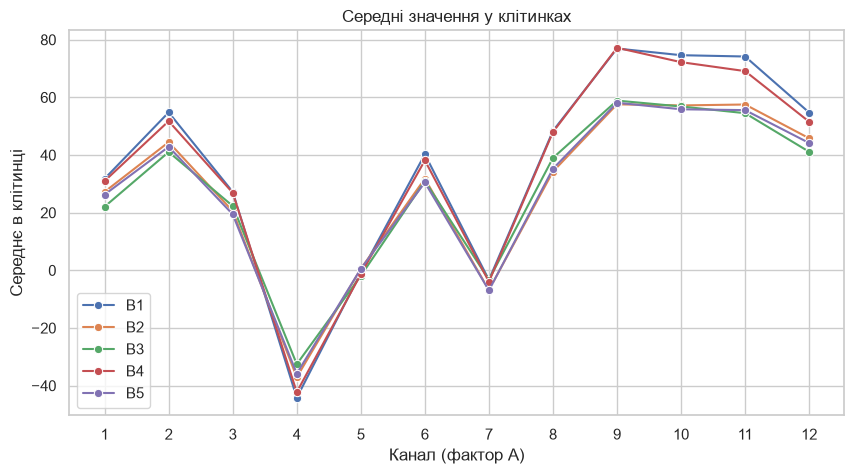

In [16]:
plt.figure(figsize=(10, 5))
for j in range(m):
    sns.lineplot(x=np.arange(1, K + 1), y=x_ij[:, j], marker='o', label=f'B{j + 1}')
plt.xticks(range(1, K + 1))
plt.xlabel('Канал (фактор A)')
plt.ylabel('Середнє в клітинці')
plt.title('Середні значення у клітинках')
plt.show()

На графіку видно, що в частинах B1 і B4 середні майже в усіх каналах більші за модулем, мабуть там більше піків. Через це фактор B і вийшов значущим.

## 4. Кореляційний аналіз

Крок 1 - нормалізація (вже зроблена в п. 1.4).

Крок 2 - кореляційна матриця $r = \frac1n X^{*T} X^*$. Параметри нумерую з 0 до 11 (параметр j = канал ch(j+1)).

In [17]:
R = data_norm.T @ data_norm / N
R_df = pd.DataFrame(R)
R_df.round(3)

,0,1,2,3,4,5,6,7,8,9,10,11
0,1.0000,0.9760,0.9010,-0.9900,0.4060,0.9550,-0.1610,0.7930,0.8580,0.9080,0.9560,0.9820
1,0.9760,1.0000,0.9730,-0.9970,0.2110,0.9970,-0.0050,0.8870,0.9290,0.9640,0.9880,0.9970
2,0.9010,0.9730,1.0000,-0.9510,-0.0130,0.9880,0.1520,0.9390,0.9530,0.9710,0.9710,0.9610
3,-0.9900,-0.9970,-0.9510,1.0000,-0.2820,-0.9860,0.0650,-0.8560,-0.9070,-0.9480,-0.9820,-0.9970
4,0.4060,0.2110,-0.0130,-0.2820,1.0000,0.1360,-0.6370,-0.0960,0.0160,0.0850,0.1800,0.2470
5,0.9550,0.9970,0.9880,-0.9860,0.1360,1.0000,0.0540,0.9130,0.9440,0.9730,0.9880,0.9900
6,-0.1610,-0.0050,0.1520,0.0650,-0.6370,0.0540,1.0000,0.2970,0.1140,0.0580,-0.0080,-0.0560
7,0.7930,0.8870,0.9390,-0.8560,-0.0960,0.9130,0.2970,1.0000,0.9800,0.9610,0.9230,0.8730
8,0.8580,0.9290,0.9530,-0.9070,0.0160,0.9440,0.1140,0.9800,1.0000,0.9930,0.9660,0.9240
9,0.9080,0.9640,0.9710,-0.9480,0.0850,0.9730,0.0580,0.9610,0.9930,1.0000,0.9890,0.9610


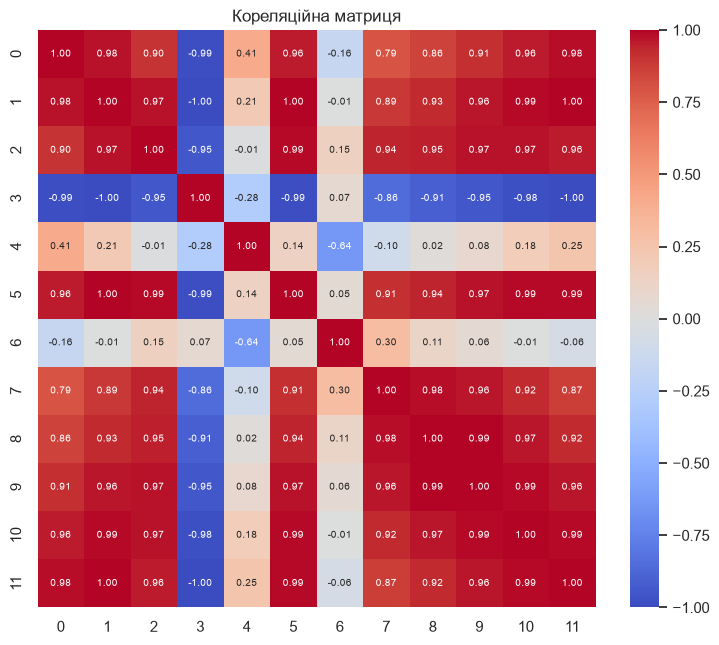

In [18]:
plt.figure(figsize=(9, 7.5))
sns.heatmap(R, cmap='coolwarm', vmin=-1, vmax=1, annot=True, fmt='.2f', annot_kws={'size': 7})
plt.title('Кореляційна матриця')
plt.show()

Крок 3 - треба вибрати 3-4 параметри з великою кореляцією між собою. Щоб не вибирати на око, перебираю всі трійки і четвірки
і беру ту, де найменший |r| усередині групи найбільший.

In [19]:
def best_group(size):
    best, best_r = None, 0
    for g in itertools.combinations(range(K), size):
        r_min = min(abs(R[i, j]) for i, j in itertools.combinations(g, 2))
        if r_min > best_r:
            best, best_r = g, r_min
    return best, best_r


print(best_group(3))
print(best_group(4))

((1, 3, 11), np.float64(0.9966144629676524))
((1, 5, 10, 11), np.float64(0.988156874570594))


Беру четвірку 1, 5, 10, 11. За a беру параметр 1 (у нього найбільші кореляції з рештою), далі за спаданням |r| з a: b = 11, c = 5, d = 10.

In [20]:
a, b, c, d = 1, 11, 5, 10
R_df.loc[[a, b, c, d], [a, b, c, d]].round(4)

,1,11,5,10
1,1.0000,0.9968,0.9965,0.9884
11,0.9968,1.0000,0.9899,0.9900
5,0.9965,0.9899,1.0000,0.9882
10,0.9884,0.9900,0.9882,1.0000


Крок 4 - частковий коефіцієнт кореляції першого порядку:
$$r_{ab(c)} = \frac{r_{ab} - r_{ac}r_{bc}}{\sqrt{(1 - r_{ac}^2)(1 - r_{bc}^2)}}$$

Крок 5 - другого порядку, через коефіцієнти першого порядку:
$$r_{ab(cd)} = \frac{r_{ab(c)} - r_{ad(c)}\,r_{bd(c)}}{\sqrt{(1 - r_{ad(c)}^2)(1 - r_{bd(c)}^2)}}$$

In [21]:
def r1(i, j, z):
    return (R[i, j] - R[i, z] * R[j, z]) / np.sqrt((1 - R[i, z] ** 2) * (1 - R[j, z] ** 2))


def r2(i, j, z1, z2):
    rij, riz, rjz = r1(i, j, z1), r1(i, z2, z1), r1(j, z2, z1)
    return (rij - riz * rjz) / np.sqrt((1 - riz ** 2) * (1 - rjz ** 2))


print('r_ab(c)  =', r1(a, b, c))
print('r_ac(b)  =', r1(a, c, b))
print('r_ab(cd) =', r2(a, b, c, d))
print('r_ac(bd) =', r2(a, c, b, d))
print('r_ad(bc) =', r2(a, d, b, c))

r_ab(c)  = 0.8764538713608376
r_ac(b)  = 0.8660076098940911
r_ab(cd) = 0.8968677272257657
r_ac(bd) = 0.8957708137253234
r_ad(bc) = -0.4741593797515667


Крок 6 - множинний коефіцієнт для a від b і c:
$$r_{a/bc} = \sqrt{\frac{r_{ab}^2 + r_{ac}^2 - 2r_{ab}r_{ac}r_{bc}}{1 - r_{bc}^2}}$$

Крок 7 - для a від b, c, d (формула дає R², потім беру корінь):
$$R_{a/bcd}^2 = 1 - (1 - r_{ab}^2)(1 - r_{ac(b)}^2)(1 - r_{ad(bc)}^2)$$

In [22]:
r_a_bc = np.sqrt((R[a, b] ** 2 + R[a, c] ** 2 - 2 * R[a, b] * R[a, c] * R[b, c]) / (1 - R[b, c] ** 2))
R2_a_bcd = 1 - (1 - R[a, b] ** 2) * (1 - r1(a, c, b) ** 2) * (1 - r2(a, d, b, c) ** 2)
print('r_a/bc   =', r_a_bc)
print('R^2_a/bcd =', R2_a_bcd)
print('R_a/bcd  =', np.sqrt(R2_a_bcd))

r_a/bc   = 0.9991967749838425
R^2_a/bcd = 0.9987552236163371
R_a/bcd  = 0.9993774180039977


Крок 8 - висновки. Щоб знайти незалежний параметр, рахую для кожного середній і максимальний |r| з іншими:

In [23]:
absR = np.abs(R - np.eye(K))
pd.DataFrame({'max |r|': absR.max(axis=1), 'середній |r|': absR.sum(axis=1) / (K - 1)}).sort_values('середній |r|').round(3)

,max |r|,середній |r|
6,0.6370,0.1460
4,0.6370,0.2100
7,0.9800,0.7740
8,0.9930,0.7800
2,0.9880,0.7970
9,0.9930,0.8010
0,0.9900,0.8080
1,0.9970,0.8110
5,0.9970,0.8110
10,0.9900,0.8130


In [24]:
print('пар з |r| >= 0.7:', sum(abs(R[i, j]) >= 0.7 for i, j in itertools.combinations(range(K), 2)))
print('кореляції параметра 6:', R[6].round(2))

пар з |r| >= 0.7: 45
кореляції параметра 6: [-0.16 -0.01  0.15  0.07 -0.64  0.05  1.    0.3   0.11  0.06 -0.01 -0.06]


**Висновки по кореляції:**
- параметри 0, 1, 2, 3, 5, 7, 8, 9, 10, 11 сильно корелюють між собою (|r| від 0.79 до 0.997), 45 пар із 66 мають |r| ≥ 0.7. Параметр 3 з усіма корелює від'ємно, схоже що в каналі ch4 сигнал інвертований;
- параметр 1 майже повністю визначається параметрами 11, 5, 10: R = 0.9994. Але й без d вже r = 0.9992, тобто d майже нічого не додає;
- часткові коефіцієнти (0.87-0.90) менші за парні (≈0.997), значить частина зв'язку між параметрами пояснюється впливом інших. r_ad(bc) = -0.47, навіть знак змінився;
- незалежний параметр є: параметр 6 (ch7), середній |r| = 0.146. Помітно він корелює тільки з параметром 4 (r = -0.64), а параметр 4 теж слабко пов'язаний з основною групою.

## 5. Спектральний аналіз

Пряме перетворення:
$$A_0 = \frac1N\sum s_i,\quad A_{N/2} = \frac1N\sum s_i\cos(\pi i),\quad A_l = \frac2N\sum s_i\cos\frac{2\pi i l}{N},\quad B_j = \frac2N\sum s_i\sin\frac{2\pi i j}{N}$$
Спектр $C_j = \sqrt{A_j^2 + B_j^2}$.

Обернене: $d_i = \sum_{j=0}^{N/2}A_j\cos\frac{2\pi j i}{N} + \sum_{j=0}^{N/2}B_j\sin\frac{2\pi j i}{N}$

Суми рахую через матриці косинусів і синусів, щоб не писати цикл на 5000×2500 (було б дуже довго). Рахую відразу для 12 каналів і модуля.

In [25]:
signals = df_ext.values          # 5000 x 13
names = list(df_ext.columns)
half = N // 2
i_ = np.arange(N)
j_ = np.arange(half + 1)
COS = np.cos(2 * np.pi * np.outer(j_, i_) / N)
SIN = np.sin(2 * np.pi * np.outer(j_, i_) / N)

A = 2 / N * (COS @ signals)
A[0] /= 2         # A_0 і A_N/2 з множником 1/N
A[half] /= 2
B = 2 / N * (SIN @ signals)
C = np.sqrt(A ** 2 + B ** 2)

Крок по частоті (частота першої синусоїди) Δf = 1/N = 1/5000 = 0.0002 на відлік, тобто перша гармоніка має період, рівний всьому запису.
Якщо fs = 500 Гц, то Δf = fs/N = 0.1 Гц.

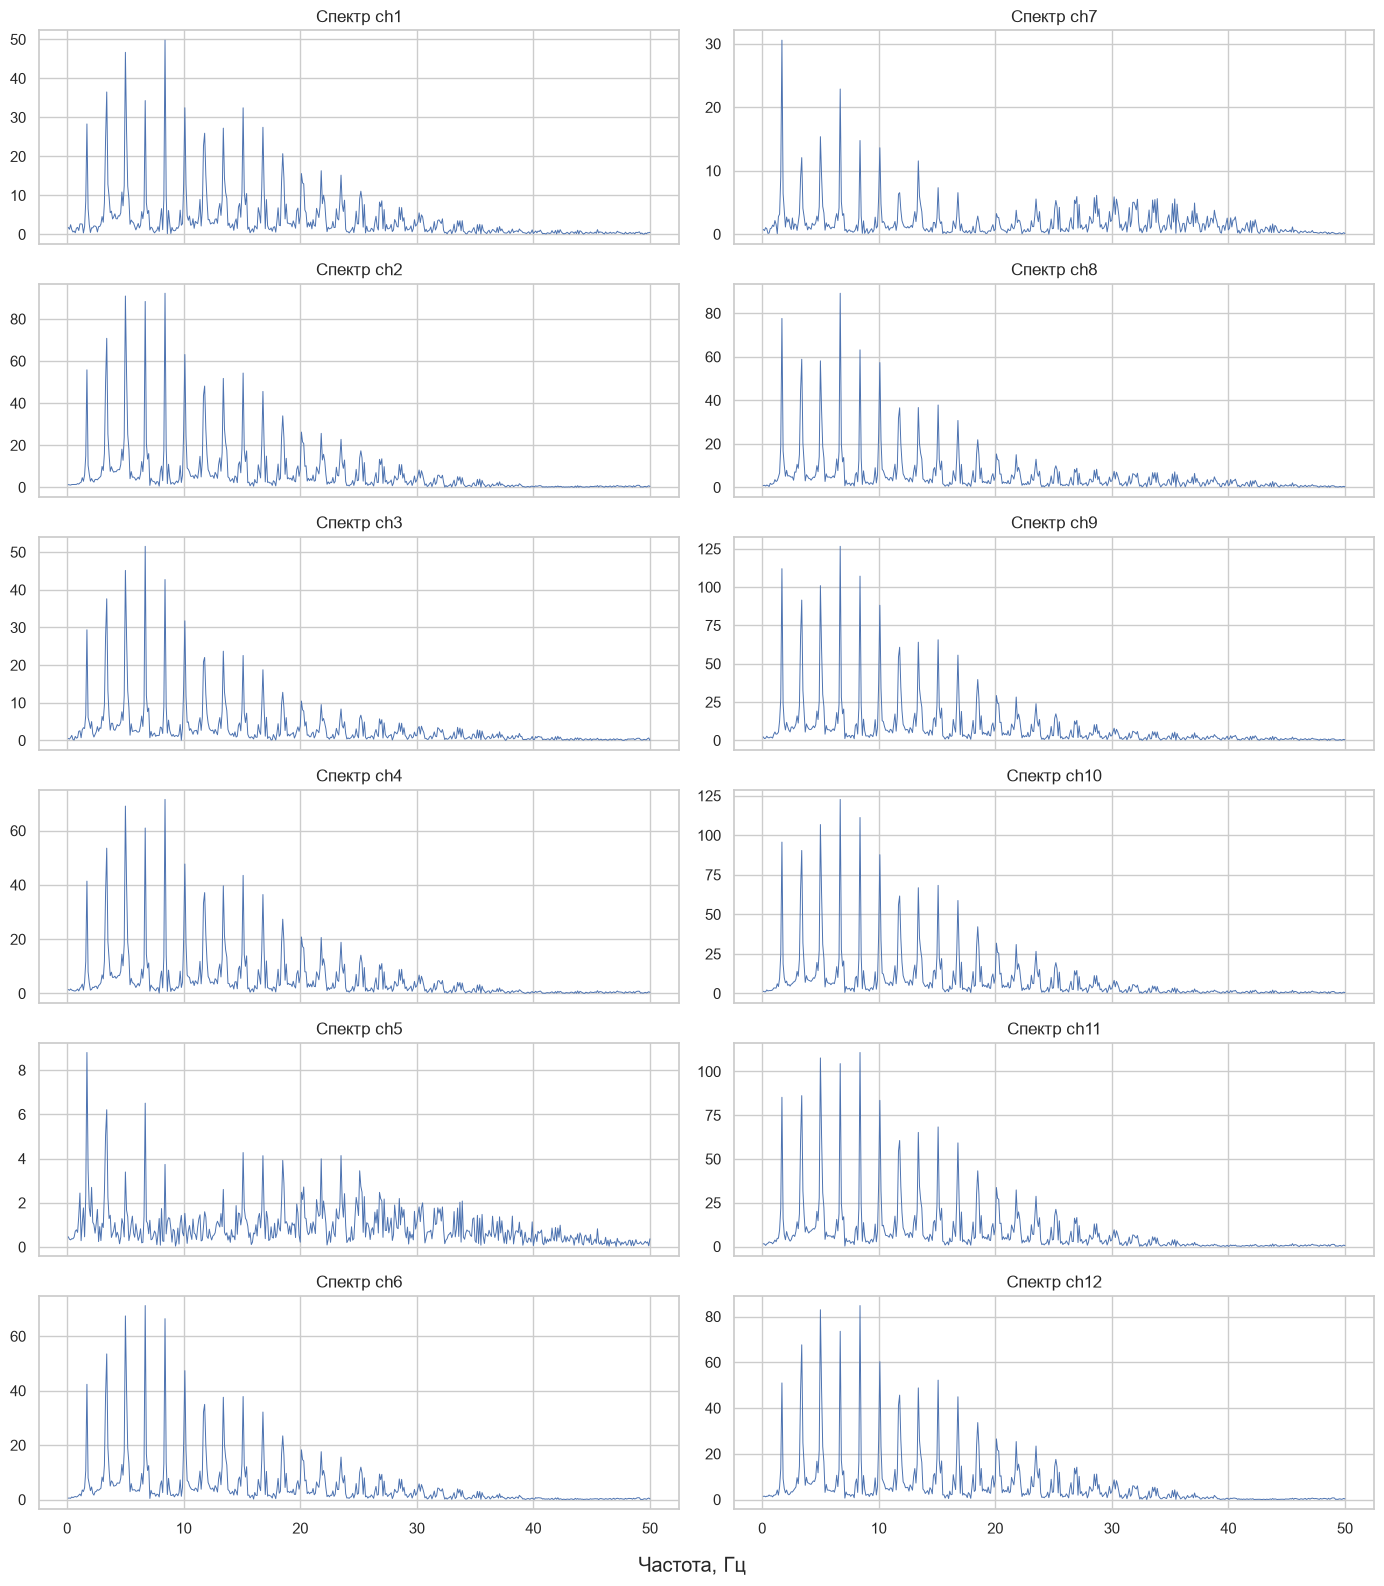

In [26]:
freqs = j_ * fs / N

fmask = (freqs > 0) & (freqs <= 50)    # без постійної складової, до 50 Гц
fig, axes = plt.subplots(6, 2, figsize=(14, 16), sharex=True)
for ax, col in zip(axes.T.ravel(), range(K)):
    sns.lineplot(x=freqs[fmask], y=C[fmask, col], ax=ax, lw=0.7)
    ax.set_title(f'Спектр {names[col]}')
fig.supxlabel('Частота, Гц')
fig.tight_layout()
plt.show()

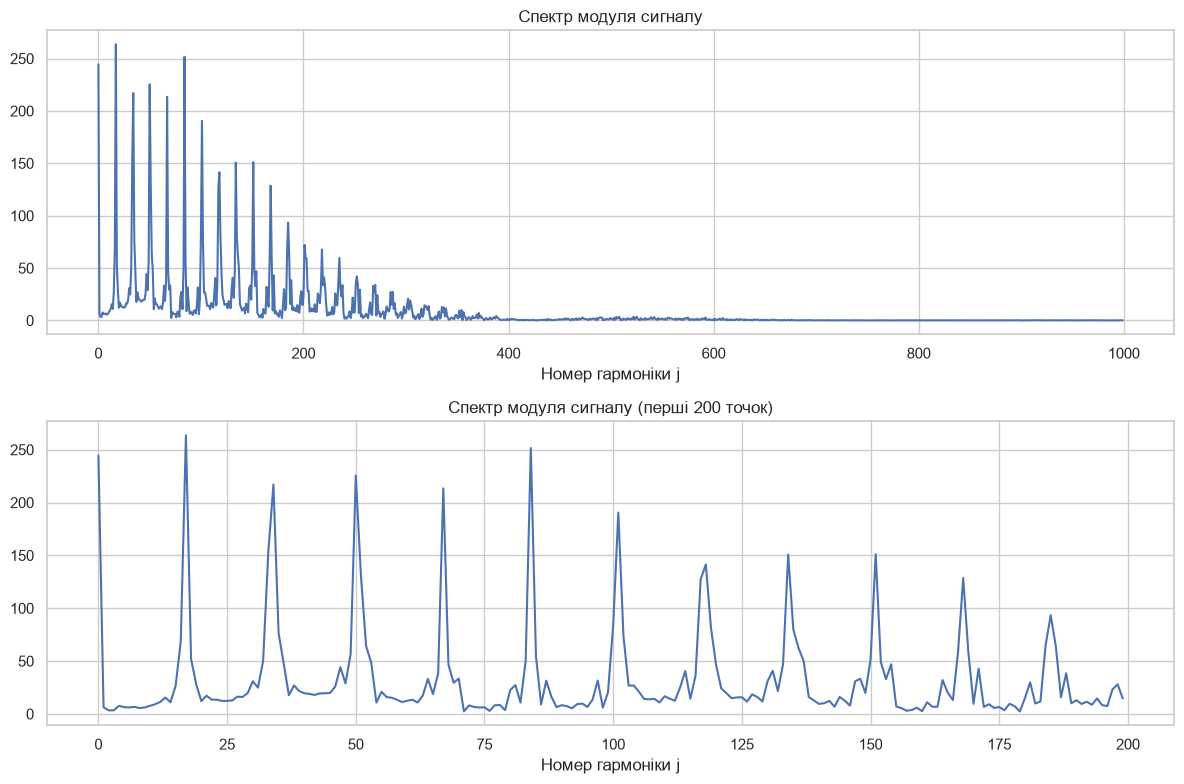

In [27]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
sns.lineplot(x=j_[:1000], y=C[:1000, 12], ax=axes[0])
axes[0].set_title('Спектр модуля сигналу')
sns.lineplot(x=j_[:200], y=C[:200, 12], ax=axes[1])
axes[1].set_title('Спектр модуля сигналу (перші 200 точок)')
for ax in axes:
    ax.set_xlabel('Номер гармоніки j')
fig.tight_layout()
plt.show()

### 5.1. Порівняння спектрів

Для кожної змінної шукаю найбільшу гармоніку (без постійної складової) і частоту, до якої набирається 95% енергії.

In [28]:
rows = []
for col, name in enumerate(names):
    j_max = 1 + np.argmax(C[1:, col])
    energy = np.cumsum(C[1:, col] ** 2) / np.sum(C[1:, col] ** 2)
    f95 = freqs[1 + np.searchsorted(energy, 0.95)]
    rows.append([name, A[0, col], j_max, freqs[j_max], C[j_max, col], f95])
spec = pd.DataFrame(rows, columns=['змінна', 'A0', 'j_max', 'f_max, Гц', 'C_max', '95% енергії до, Гц']).set_index('змінна')
spec

,A0,j_max,"f_max, Гц",C_max,"95% енергії до, Гц"
змінна,,,,,
ch1,27.6762,84,8.4000,49.7948,25.1000
ch2,46.9822,84,8.4000,92.2141,23.1000
ch3,23.2767,67,6.7000,51.5463,21.8000
ch4,-38.3901,84,8.4000,71.5129,23.5000
ch5,-0.6045,17,1.7000,8.7980,35.4000
ch6,34.3244,67,6.7000,71.2425,22.0000
ch7,-4.8635,17,1.7000,30.5680,36.2000
ch8,40.9651,67,6.7000,89.1881,22.2000
ch9,65.7490,67,6.7000,126.6028,20.9000


In [29]:
# період піків через автокореляцію модуля
x = module - module.mean()
ac = np.correlate(x, x, mode='full')[N - 1:]
lag = 150 + np.argmax(ac[150:1000])     # шукаю від 150 відліків, щоб не потрапити в нульовий зсув
print('період =', lag, 'відліків =', lag / fs, 'с')
print('f0 =', fs / lag, 'Гц,  j =', N / lag)

період = 298 відліків = 0.596 с
f0 = 1.6778523489932886 Гц,  j = 16.778523489932887


Піки повторюються кожні 298 відліків (0.596 с), основна частота f0 ≈ 1.68 Гц, це гармоніка j ≈ 16.8 (для ЕКГ це приблизно 101 удар/хв).
Найбільші гармоніки в каналах j = 17, 67, 84, тобто це 1-ша, 4-та і 5-та гармоніки f0.

Спектри в усіх каналах схожі: піки на частотах, кратних f0, і з ростом частоти амплітуда падає. 95% енергії лежить нижче 21-36 Гц.
Різниця між каналами тільки в амплітудах і постійній складовій. У ch5 і ch7 амплітуди найменші, а спектр ширший (до 35-36 Гц), і саме ці канали слабо корелюють з іншими.

### 5.2. Обернене перетворення

In [30]:
restored = COS.T @ A + SIN.T @ B
err = np.abs(restored - signals)
print('максимальна похибка по змінних:')
print(pd.Series(err.max(axis=0), index=names).to_string(float_format='{:.2e}'.format))

максимальна похибка по змінних:
ch1      1.91e-10
ch2      3.12e-10
ch3      1.52e-10
ch4      2.51e-10
ch5      3.07e-11
ch6      2.29e-10
ch7      6.87e-11
ch8      2.67e-10
ch9      4.46e-10
ch10     4.30e-10
ch11     3.95e-10
ch12     2.95e-10
module   9.78e-10


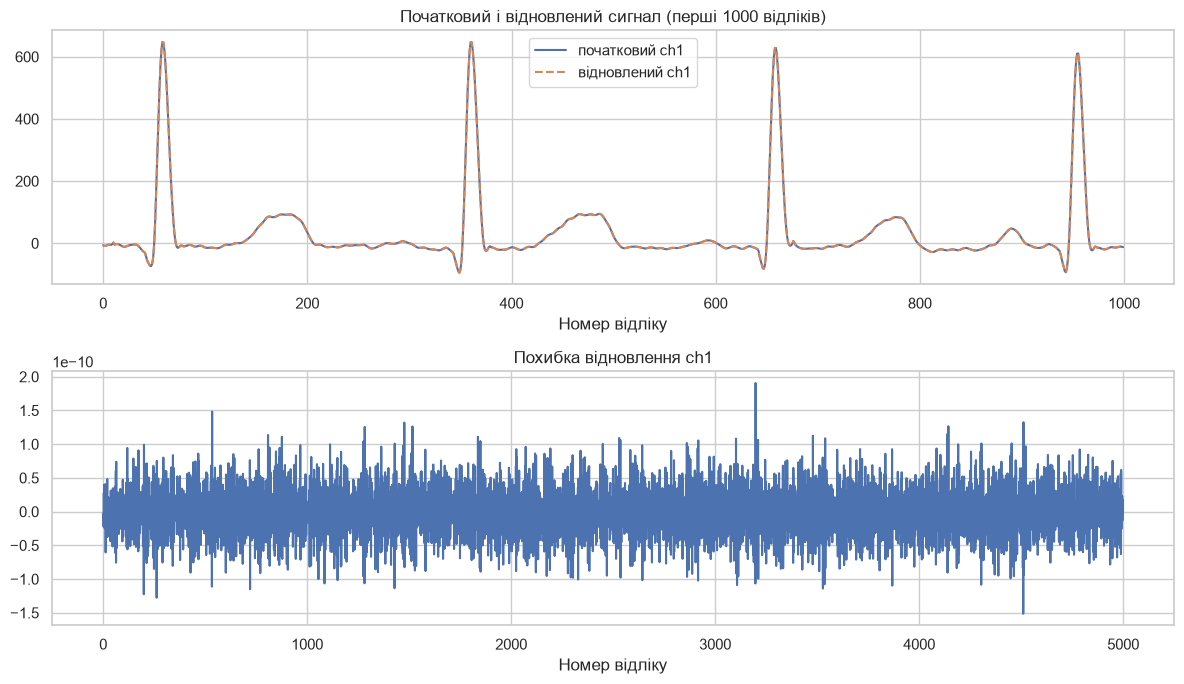

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
sns.lineplot(x=t[:1000], y=signals[:1000, 0], ax=axes[0], label='початковий ch1')
sns.lineplot(x=t[:1000], y=restored[:1000, 0], ax=axes[0], label='відновлений ch1', linestyle='--')
axes[0].set_title('Початковий і відновлений сигнал (перші 1000 відліків)')
sns.lineplot(x=t, y=restored[:, 0] - signals[:, 0], ax=axes[1])
axes[1].set_title('Похибка відновлення ch1')
for ax in axes:
    ax.set_xlabel('Номер відліку')
fig.tight_layout()
plt.show()

Похибка від 3e-11 до 1e-9, це просто округлення чисел, тобто обернене перетворення повністю відновлює вихідні дані.

## Висновки

1. Сигнал у всіх каналах квазіперіодичний з гострими піками. Розподіли не нормальні (асиметрія до ±4.2, ексцес до 17.5), за χ² гіпотеза відхиляється для всіх каналів. Дані нормалізовані.
2. Однофакторний аналіз: дисперсії каналів неоднакові (Кохрен), номер каналу значуще впливає на середнє: F = 163.67 > 1.79.
3. Двофакторний аналіз: значущі і канал (F = 248.91 > 2.01), і частина запису (F = 11.87 > 2.58), взаємодії немає (0.66 < 1.37).
4. Кореляційний аналіз: 10 з 12 параметрів сильно корельовані, для a = 1, b = 11, c = 5, d = 10 множинний коефіцієнт R = 0.9994. Параметр 6 (ch7) практично незалежний.
5. Спектральний аналіз: крок по частоті 1/N (0.1 Гц при 500 Гц), спектри складаються з гармонік f0 ≈ 1.68 Гц. Обернене перетворення відновлює дані з похибкою не більше 1e-9.